# Analyse exploratoire des commandes Olist

**Objectif du projet** : estimer, au moment de l'achat, le délai de livraison d'une commande, puis
proposer une promesse de livraison plus courte que celle d'Olist, sans augmenter le taux de retard.

Avant toute modélisation, ce notebook répond à quatre questions :
- quelles commandes garder, et pourquoi
- à quoi ressemblent la cible (le délai réel) et la référence à battre (la promesse d'Olist)
- quels facteurs semblent influencer le délai
- quelles précautions en tirer pour la validation et les variables

Les données viennent de `charger_commandes()`, qui exécute la requête `sql/commandes.sql` : une ligne
par commande livrée. Les colonnes préfixées `apres_achat_` ne sont connues qu'après l'achat : elles
servent ici à l'analyse, jamais au modèle.

*Prérequis : les données dans `data/raw/` (voir `data/README.md`) et le package installé
(`pip install -e .`).*

In [1]:
%load_ext autoreload
%autoreload 2

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from olist_promesse.donnees import DOSSIER_DONNEES, FIN_PERIODE, charger_commandes, selectionner_commandes
from olist_promesse.variables import distance_km

BLEU, ORANGE, GRIS = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.labelcolor": GRIS,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.titlelocation": "left",
})

## 1. Sélection des commandes

In [2]:
with duckdb.connect() as con:
    con.execute(f"SET file_search_path = '{DOSSIER_DONNEES}'")
    con.sql("""
        SELECT
            COUNT(*) AS commandes,
            COUNT(*) FILTER (WHERE order_status = 'delivered') AS livrees,
            COUNT(*) FILTER (WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL) AS livrees_avec_date
        FROM 'olist_orders_dataset.csv'
    """).show()

commandes = charger_commandes()
retenues, entonnoir = selectionner_commandes(commandes)
entonnoir

┌───────────┬─────────┬───────────────────┐
│ commandes │ livrees │ livrees_avec_date │
│   int64   │  int64  │       int64       │
├───────────┼─────────┼───────────────────┤
│     99441 │   96478 │             96470 │
└───────────┴─────────┴───────────────────┘



,etape,restantes,retirees
0,Commandes livrées (extraction SQL),96470,0
1,Achat à partir de 2017,96203,267
2,Achat avant août 2018,89852,6351
3,Un seul vendeur,88692,1160


Sur les 99 441 commandes du jeu, la requête SQL garde les 96 470 commandes livrées dont la date de
livraison est connue : la cible n'existe que pour elles. Trois règles s'appliquent ensuite, dans
`selectionner_commandes()` :
- achat à partir de 2017 (267 commandes retirées) : fin 2016 correspond au lancement de la
  plateforme, avec très peu de commandes et aucune en novembre
- achat avant août 2018 (6 351 retirées) : les commandes d'août sont biaisées, voir ci-dessous
- un seul vendeur (1 160 retirées) : chaque vendeur expédie son propre colis, mais la commande
  n'a qu'une date de livraison, sans qu'on sache à quel colis elle correspond

Il reste **88 692 commandes**, soit 92 % des commandes livrées. Les commandes incomplètes (distance ou
catégorie manquante) sont conservées : l'API en recevra aussi en production, et le pipeline traitera
ces valeurs manquantes.

### Pourquoi s'arrêter à fin juillet 2018 ?

Livraisons avant le 4 septembre 2018 : 99.96%


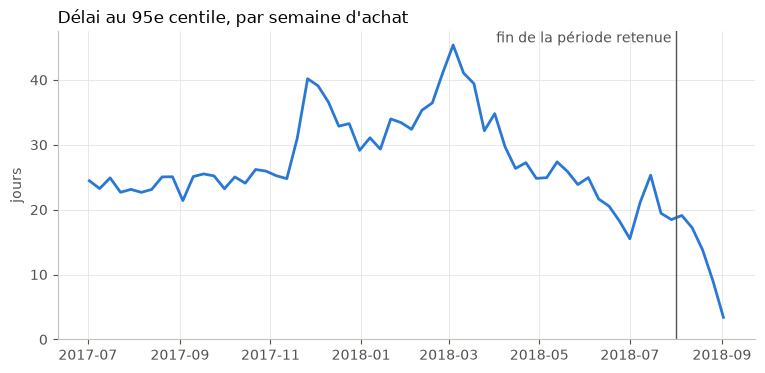

In [3]:
livraison = commandes["order_purchase_timestamp"] + pd.to_timedelta(commandes["delai_jours"], unit="D")
print(f"Livraisons avant le 4 septembre 2018 : {(livraison < '2018-09-04').mean():.2%}")

recentes = commandes[commandes["order_purchase_timestamp"] >= "2017-07-01"]
q95_par_semaine = recentes.groupby(pd.Grouper(key="order_purchase_timestamp", freq="W"))["delai_jours"].quantile(0.95)

fig, ax = plt.subplots()
ax.plot(q95_par_semaine.index, q95_par_semaine.values, color=BLEU, lw=2)
ax.axvline(FIN_PERIODE, color=GRIS, lw=1)
ax.text(FIN_PERIODE, ax.get_ylim()[1], "fin de la période retenue ", color=GRIS, ha="right", va="top")
ax.set(title="Délai au 95e centile, par semaine d'achat", ylabel="jours", ylim=(0, None))
plt.show()

In [4]:
with duckdb.connect() as con:
    con.execute(f"SET file_search_path = '{DOSSIER_DONNEES}'")
    con.sql("""
        SELECT
            strftime(order_purchase_timestamp, '%Y-%m') AS mois_achat,
            COUNT(*) AS commandes,
            round(100 * AVG((order_status = 'delivered')::INT), 1) AS livrees_pct
        FROM 'olist_orders_dataset.csv'
        WHERE order_purchase_timestamp >= '2018-05-01' AND order_purchase_timestamp < '2018-09-01'
        GROUP BY ALL
        ORDER BY mois_achat
    """).show()

fin_periode = retenues.loc[retenues["order_purchase_timestamp"] >= "2018-04-01", "delai_jours"]
print(f"Achats d'avril à juillet 2018 : 95e centile du délai {fin_periode.quantile(0.95):.1f} j, "
      f"délais de plus de 33 jours {fin_periode.gt(33).mean():.1%}")

┌────────────┬───────────┬─────────────┐
│ mois_achat │ commandes │ livrees_pct │
│  varchar   │   int64   │   double    │
├────────────┼───────────┼─────────────┤
│ 2018-05    │      6873 │        98.2 │
│ 2018-06    │      6167 │        98.9 │
│ 2018-07    │      6292 │        97.9 │
│ 2018-08    │      6512 │        97.5 │
└────────────┴───────────┴─────────────┘

Achats d'avril à juillet 2018 : 95e centile du délai 24.1 j, délais de plus de 33 jours 1.6%


Les données s'arrêtent début septembre 2018 : 99,96 % des livraisons ont lieu avant le 4 septembre.
Pour un achat fin août, seules les livraisons rapides ont eu le temps d'arriver, et les commandes
encore en transit ne figurent pas dans le jeu.

Le taux de commandes livrées ne détecte rien : 97,5 % en août contre 97,9 % en juillet. La
distribution des délais, elle, s'effondre : le 95ᵉ centile hebdomadaire, qui varie entre 20 et
45 jours de juillet 2017 à juillet 2018, tombe de 19 jours début août à 3,4 jours la dernière
semaine. Un tel délai n'a rien de réel : il ne reste que les commandes livrées très vite (avant la fin des données). Garder août ferait paraître les livraisons plus rapides qu'elles ne le sont, à l'entraînement comme à l'évaluation.

**Limite restante** : un achat du 31 juillet n'a qu'environ 34 jours d'observation. D'avril à
juillet 2018, 1,6 % des délais dépassent 33 jours : quelques commandes très lentes de fin juillet
peuvent donc manquer. Cela reste bien au-delà du 95ᵉ centile de la période (24 jours), que visera
la promesse.

## 2. À quoi ressemble la cible ?

count    88692.0
mean        12.9
std          9.7
min          0.5
50%         10.7
90%         23.8
95%         30.1
99%         46.7
max        209.6
Name: delai_jours, dtype: float64

Coefficient d'asymétrie : 3.82
Part de la variance portée par les 10 % de délais les plus longs : 68.4%


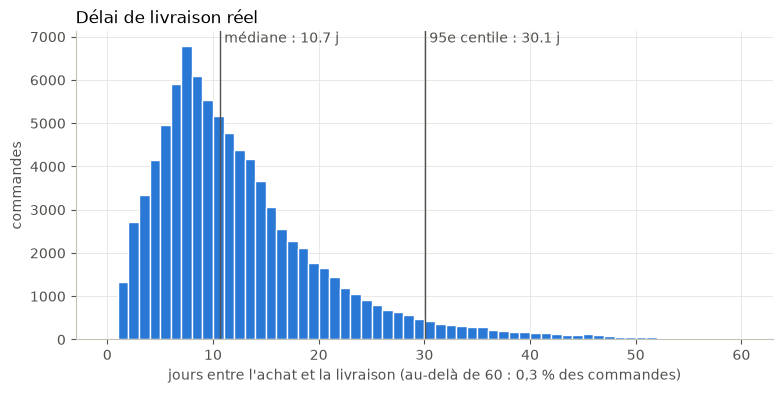

In [5]:
delai = retenues["delai_jours"]
display(delai.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))

# Pour un modèle qui prédirait toujours le délai moyen, l'erreur quadratique moyenne est la variance :
# on mesure la part qu'y prennent les 10 % de délais les plus longs
ecarts_carres = (delai - delai.mean()) ** 2
part_queue = ecarts_carres[delai >= delai.quantile(0.9)].sum() / ecarts_carres.sum()
print(f"Coefficient d'asymétrie : {delai.skew():.2f}")
print(f"Part de la variance portée par les 10 % de délais les plus longs : {part_queue:.1%}")

fig, ax = plt.subplots()
ax.hist(delai, bins=range(0, 61), color=BLEU, edgecolor="white", linewidth=1)
for q, nom in [(0.5, "médiane"), (0.95, "95e centile")]:
    valeur = delai.quantile(q)
    ax.axvline(valeur, color=GRIS, lw=1)
    ax.text(valeur, ax.get_ylim()[1], f" {nom} : {valeur:.1f} j", color=GRIS, va="top")
ax.set(title="Délai de livraison réel", xlabel="jours entre l'achat et la livraison (au-delà de 60 : 0,3 % des commandes)", ylabel="commandes")
plt.show()

La cible est fortement asymétrique, avec une longue queue à droite : coefficient d'asymétrie de 3,8,
moyenne de 12,9 jours pour une médiane de 10,7 jours, et un maximum de 210 jours.

Cette queue pèse lourd dans toute erreur quadratique : pour un modèle qui prédirait toujours le
délai moyen, les 10 % de délais les plus longs porteraient 68 % de l'erreur. Deux conséquences :
- **la MAE (en jours) sera la métrique d'estimation** : chaque jour d'erreur y a le même poids, là
  où la RMSE serait dominée par quelques commandes très lentes. La MAE est minimisée par la médiane :
  le modèle d'estimation visera donc le délai médian
- **la promesse visera un quantile élevé** : c'est précisément cette queue qu'elle doit couvrir pour
  limiter les retards

## 3. La référence à battre : la promesse d'Olist

Délai promis moyen (j)                   24.23
Délai réel moyen (j)                     12.92
MAE de la promesse (j)                   12.94
Taux de retard (%)                        6.91
Taux de retard, horodatages bruts (%)     8.06
dtype: float64

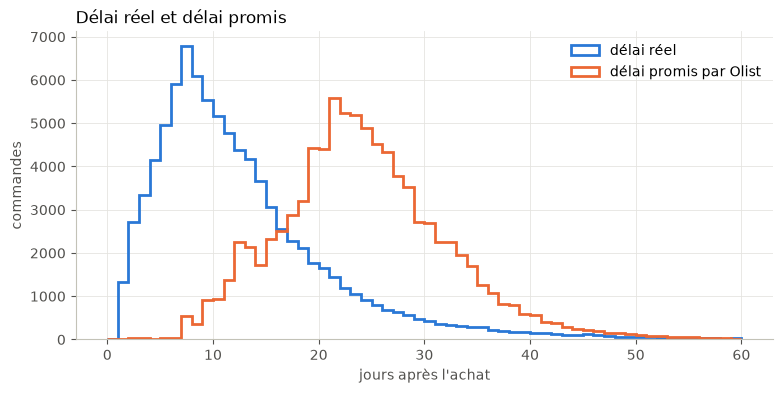

In [6]:
ecart = retenues["promesse_jours"] - delai
# La date promise est un jour (stocké à minuit) : livrer le jour promis, c'est être à l'heure.
en_retard = delai >= retenues["promesse_jours"] + 1

display(pd.Series({
    "Délai promis moyen (j)": retenues["promesse_jours"].mean(),
    "Délai réel moyen (j)": delai.mean(),
    "MAE de la promesse (j)": ecart.abs().mean(),
    "Taux de retard (%)": 100 * en_retard.mean(),
    "Taux de retard, horodatages bruts (%)": 100 * (delai > retenues["promesse_jours"]).mean(),
}).round(2))

fig, ax = plt.subplots()
ax.hist(delai, bins=range(0, 61), histtype="step", lw=2, color=BLEU, label="délai réel")
ax.hist(retenues["promesse_jours"], bins=range(0, 61), histtype="step", lw=2, color=ORANGE, label="délai promis par Olist")
ax.legend(frameon=False)
ax.set(title="Délai réel et délai promis", xlabel="jours après l'achat", ylabel="commandes")
plt.show()

In [7]:
note = retenues["apres_achat_note_avis"]
pd.DataFrame({
    "commandes": en_retard.value_counts(),
    "note moyenne": note.groupby(en_retard).mean(),
    "avis 1 ou 2 étoiles (%)": 100 * (note <= 2).groupby(en_retard).mean(),
}).rename(index={False: "à l'heure", True: "en retard"}).round(2)

,commandes,note moyenne,avis 1 ou 2 étoiles (%)
à l'heure,82567,4.30,8.78
en retard,6125,2.23,62.11


Une métrique n'a de sens que comparée à une référence : ici, la promesse qu'Olist affiche aujourd'hui.

Olist promet en moyenne **24,2 jours pour 12,9 jours réels**, presque le double. En contrepartie,
seules **6,9 %** des commandes arrivent après la date promise. Le retard est compté au jour près, c'est-à-dire que la date promise est un jour (stockée à minuit) et donc une livraison le jour promis est à l'heure. Comparer les horodatages bruts compterait ces livraisons en retard et donnerait 8,1 %.

Cette prudence se comprend facilement lorsque l'on regarde l'opinion du client : un retard coûte très cher en satisfaction. La note moyenne tombe de
4,30 à 2,23, et la part d'avis à 1 ou 2 étoiles passe de 9 % à 62 %.

D'où l'objectif du projet : **raccourcir la promesse sans dépasser 6,9 % de retard**. La MAE de la
promesse d'Olist (12,9 jours) n'est pas une référence pertinente, car une promesse ne vise pas le
délai moyen. Notre promesse se comparera à celle d'Olist à taux de retard égal, sur le délai
promis moyen.

## 4. Comment les délais évoluent-ils dans le temps ?

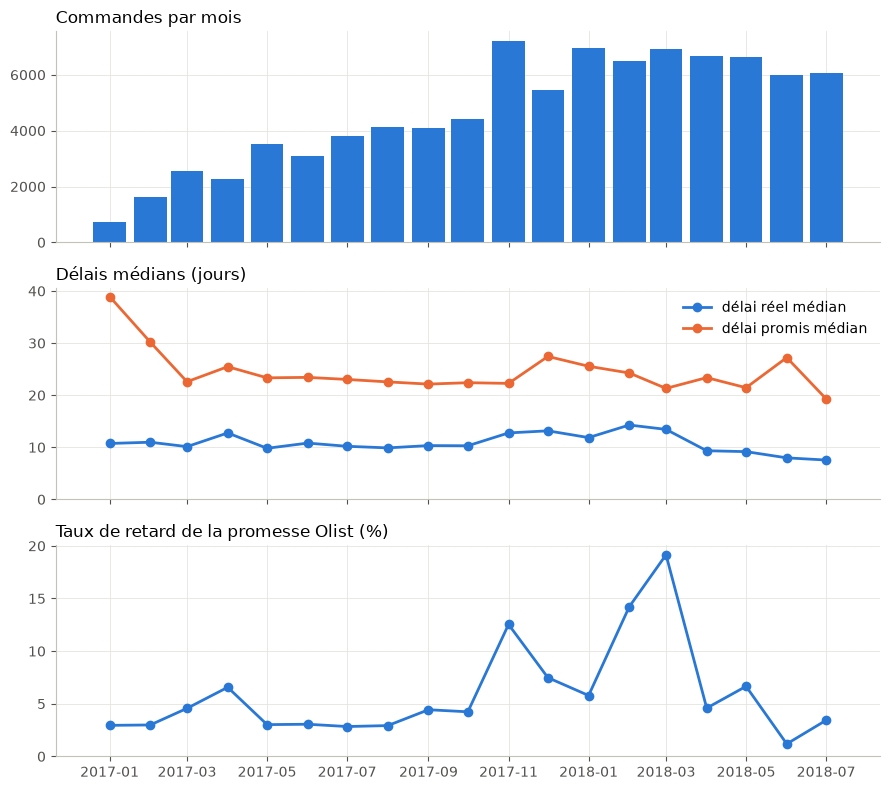

In [8]:
mois = retenues["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
par_mois = pd.DataFrame({
    "commandes": retenues.groupby(mois).size(),
    "délai réel médian": delai.groupby(mois).median(),
    "délai promis médian": retenues["promesse_jours"].groupby(mois).median(),
    "taux de retard (%)": 100 * en_retard.groupby(mois).mean(),
})

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
ax1.bar(par_mois.index, par_mois["commandes"], width=25, color=BLEU)
ax1.set(title="Commandes par mois")
ax2.plot(par_mois.index, par_mois["délai réel médian"], color=BLEU, lw=2, marker="o", label="délai réel médian")
ax2.plot(par_mois.index, par_mois["délai promis médian"], color=ORANGE, lw=2, marker="o", label="délai promis médian")
ax2.set(title="Délais médians (jours)", ylim=(0, None))
ax2.legend(frameon=False)
ax3.plot(par_mois.index, par_mois["taux de retard (%)"], color=BLEU, lw=2, marker="o")
ax3.set(title="Taux de retard de la promesse Olist (%)", ylim=(0, None))
fig.tight_layout()
plt.show()

Le volume est multiplié par 9 entre janvier 2017 et janvier 2018, avec un pic en novembre 2017
(Black Friday), puis se stabilise autour de 6 000 à 7 000 commandes par mois.

Le délai réel n'est pas stable. Autour de 10 jours pendant la majeure partie de 2017, il monte à
13 jours en fin d'année puis à 14,3 jours en février 2018, avant de descendre à 7,6 jours en juillet
2018.
La promesse d'Olist, elle, ne suit pas ces variations. En février et mars 2018, le délai réel augmente alors que la promesse raccourcit, et le taux de retard grimpe alors à 14,2 % puis 19,2 %. À l'inverse, en juin 2018, la promesse s'allonge alors que le délai baisse, et le retard tombe à 1,2 %.

La relation change dans le temps et le taux global de 6,9 % cache donc des mois à près de 20 %.

Deux conséquences majeures :
- **la validation sera temporelle** : entraînement jusqu'à fin avril 2018, test de mai à juillet
  2018. Un découpage aléatoire mélangerait passé et futur, et donnerait une performance trop
  optimiste
- **le taux de retard sera suivi mois par mois**, et pas seulement en moyenne sur la période de test.

## 5. Quel rôle joue la géographie ?

count    88249.0
mean       607.3
std        595.8
min          0.0
25%        196.2
50%        439.4
75%        805.5
max       3398.5
dtype: float64

Corrélation de Spearman distance-délai : 0.54


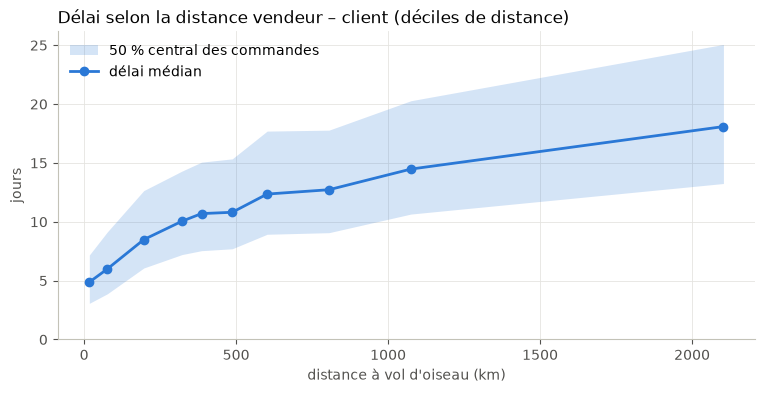

In [9]:
distance = distance_km(retenues["seller_lat"], retenues["seller_lng"], retenues["customer_lat"], retenues["customer_lng"])
display(distance.describe().round(1))

print(f"Corrélation de Spearman distance-délai : {delai.corr(distance, method='spearman'):.2f}")

tranche = pd.qcut(distance, 10)
par_tranche = delai.groupby(tranche, observed=True).quantile([0.25, 0.5, 0.75]).unstack()
centre = distance.groupby(tranche, observed=True).median()

fig, ax = plt.subplots()
ax.fill_between(centre, par_tranche[0.25], par_tranche[0.75], color=BLEU, alpha=0.2, lw=0, label="50 % central des commandes")
ax.plot(centre, par_tranche[0.5], color=BLEU, lw=2, marker="o", label="délai médian")
ax.legend(frameon=False, loc="upper left")
ax.set(title="Délai selon la distance vendeur – client (déciles de distance)", xlabel="distance à vol d'oiseau (km)", ylabel="jours", ylim=(0, None))
plt.show()

,size,median
False,57345,13.087928
True,31347,6.818368


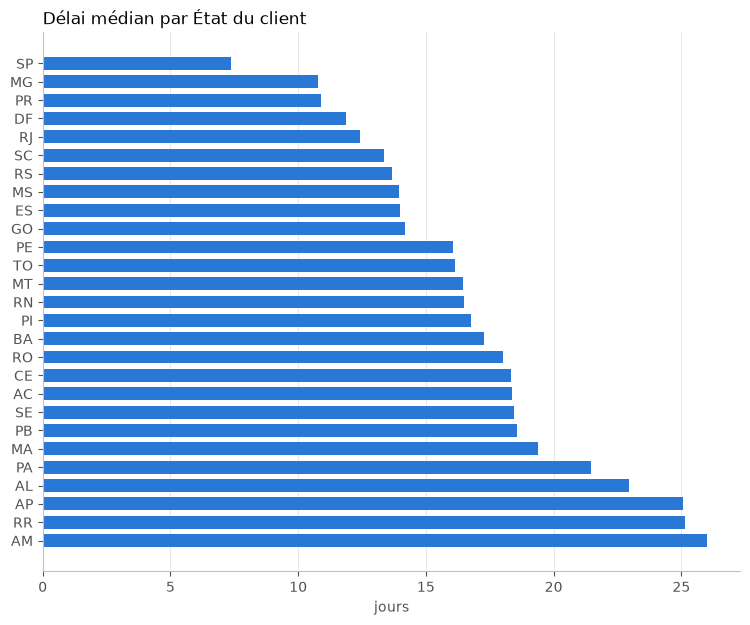

In [10]:
meme_etat = retenues["seller_state"] == retenues["customer_state"]
display(delai.groupby(meme_etat).agg(["size", "median"]))

par_etat = delai.groupby(retenues["customer_state"]).median().sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(par_etat.index, par_etat.values, color=BLEU, height=0.7)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set(title="Délai médian par État du client", xlabel="jours")
plt.show()

La première version de cette analyse donnait une distance maximale
de 8 678 km, alors que le Brésil mesure environ 4 300 km d'un bout à l'autre : 31 points GPS sur un
million tombaient hors du pays. Ils sont désormais écartés dans la requête d'extraction, par un filtre sur les latitudes et longitudes. La distance maximale après correction tombe à 3 398 km, nettement plus cohérent.

La distance est un facteur majeur du délai : corrélation de Spearman de 0,54, et un délai
médian de 4,9 jours pour le décile le plus proche contre 18,1 jours pour le plus lointain. Mais elle
n'explique pas tout, à distance égale la dispersion des délais reste large : la moitié centrale s'étale sur 4 jours pour les commandes proches, et jusqu'à 12 jours pour les plus lointaines.

Les commandes livrées dans l'État du vendeur sont deux fois plus rapides et représentent
35 % des commandes, avec un délai médian de 6,8 jours contre 13,1 jours pour les autres.

L'État du client compte aussi, de 7,4 jours (SP) à 26 jours (AM) de délai médian. Il capte à la fois l'éloignement des vendeurs, concentrés dans le Sud-Est (71 % des commandes viennent d'un
vendeur de l'État de São Paulo), et la qualité du réseau logistique local, plus faible dans le Nord.
À noter que certaines médianes reposent sur peu de commandes (40 pour RR, 65 pour AP) et sont donc à lire avec prudence.

## 6. Qui sont les vendeurs ?

In [11]:
par_vendeur = retenues["seller_id"].value_counts()
debut_test = pd.Timestamp("2018-05-01")
avant = retenues["order_purchase_timestamp"] < debut_test
inedits = ~retenues.loc[~avant, "seller_id"].isin(retenues.loc[avant, "seller_id"])

pd.Series({
    "Vendeurs": len(par_vendeur),
    "Commandes par vendeur (médiane)": par_vendeur.median(),
    "Vendeurs de moins de 10 commandes (%)": 100 * (par_vendeur < 10).mean(),
    "Commandes des 10 % plus gros vendeurs (%)": 100 * par_vendeur.head(len(par_vendeur) // 10).sum() / len(retenues),
    "Commandes mai-juil. 2018 de vendeurs inédits (%)": 100 * inedits.mean(),
}).round(1)

Vendeurs                                            2774.0
Commandes par vendeur (médiane)                        6.0
Vendeurs de moins de 10 commandes (%)                 59.6
Commandes des 10 % plus gros vendeurs (%)             67.7
Commandes mai-juil. 2018 de vendeurs inédits (%)      12.7
dtype: float64

Les vendeurs sont nombreux et très inégaux : 2 774 vendeurs, 6 commandes par vendeur en médiane.
59,6 % d'entre eux ont moins de 10 commandes sur la période, tandis que les 10 % plus gros vendeurs
réalisent 67,7 % des commandes. Le marché se renouvelle aussi : 12,7 % des commandes de mai à juillet
2018 viennent de vendeurs jamais vus auparavant.

L'historique d'un vendeur (son délai habituel) est donc une variable prometteuse, à deux conditions :
- le calculer uniquement sur le passé, sinon le modèle verrait les délais qu'il doit prédire
  (fuite)
- prévoir un repli pour les vendeurs inédits ou peu actifs, qui représenteront environ une
  commande sur huit en production

La validation temporelle teste naturellement ce cas, puisque la période de test contient ces
vendeurs inédits.

## 7. Les étapes du délai et quelques pistes

In [12]:
achat = retenues["order_purchase_timestamp"]
validation = retenues["apres_achat_validation"]
transporteur = retenues["apres_achat_remise_transporteur"]
livraison = achat + pd.to_timedelta(delai, unit="D")

etapes = pd.DataFrame({
    "achat → validation": validation - achat,
    "validation → remise au transporteur": transporteur - validation,
    "remise au transporteur → livraison": livraison - transporteur,
}).apply(lambda duree: duree.dt.total_seconds() / 86400)
display(etapes.agg(["median", "mean"]).T.round(2))

paiement = retenues["type_paiement_principal"]
display(pd.DataFrame({
    "commandes (%)": 100 * paiement.value_counts(normalize=True),
    "validation médiane (h)": 24 * etapes["achat → validation"].groupby(paiement).median(),
    "délai médian (j)": delai.groupby(paiement).median(),
}).round(1))

jours = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
(
    delai.groupby(achat.dt.day_of_week).median()
    .rename(index=dict(enumerate(jours)))
    .rename_axis("jour d'achat")
    .round(1)
)

,median,mean
achat → validation,0.01,0.43
validation → remise au transporteur,1.85,2.83
remise au transporteur → livraison,7.24,9.67


,commandes (%),validation médiane (h),délai médian (j)
type_paiement_principal,,,
boleto,20.1,29.2,11.8
credit_card,75.4,0.3,10.3
debit_card,1.3,0.9,9.2
voucher,3.1,0.3,10.6


jour d'achat
lundi        9.7
mardi        9.6
mercredi    10.1
jeudi       11.4
vendredi    11.7
samedi      11.2
dimanche    10.0
Name: delai_jours, dtype: float64

Le délai se décompose en trois étapes : la validation du paiement, la préparation du colis par le
vendeur jusqu'à sa remise au transporteur, puis le transport jusqu'au client. En moyenne, la
validation prend 0,4 jour, la préparation 2,8 jours et **le transport 9,7 jours, soit les trois
quarts du délai**.

Ces étapes sont inconnues au moment de l'achat (hors du modèle), mais deux informations connues à l'achat en captent une partie :
- **le moyen de paiement** : le boleto (20 % des commandes) met 29 heures à être validé en médiane,
  contre moins d'une heure par carte. Le délai médian passe de 10,3 jours (carte de crédit) à
  11,8 jours (boleto) ;
- **le jour d'achat** : une commande passée le jeudi ou le vendredi est livrée en 11,4 à 11,7 jours
  en médiane, contre 9,6 à 9,7 jours le lundi ou le mardi. Hypothèse instinctive : la préparation et
  l'expédition s'interrompent pendant le week-end.

Ce sont des écarts bruts, le moyen de paiement ou le jour d'achat peuvent être liés à d'autres
facteurs comme la région du client par exemple. Le modèle dira s'ils apportent une information propre.

## 8. Les données sont-elles saines ?

In [13]:
pd.Series({
    "Remise au transporteur avant l'achat": (transporteur < achat).sum(),
    "Remise au transporteur avant la validation": (transporteur < validation).sum(),
    "Livraison avant la remise au transporteur": (livraison < transporteur).sum(),
    "Délai de plus de 100 jours": (delai > 100).sum(),
    "Distance manquante": distance.isna().sum(),
    "Catégorie manquante": retenues["categorie_principale"].isna().sum(),
})

Remise au transporteur avant l'achat           117
Remise au transporteur avant la validation    1232
Livraison avant la remise au transporteur        3
Délai de plus de 100 jours                      64
Distance manquante                             443
Catégorie manquante                           1303
dtype: int64

Les données sont saines pour notre usage :
- les incohérences de dates (117 remises au transporteur avant l'achat, 1 232 avant la
  validation) touchent les colonnes `apres_achat_`, pas la cible, qui ne dépend que des dates
  d'achat et de livraison. Les 3 livraisons antérieures à la remise au transporteur sont
  négligeables. Tout est conservé
- les 64 délais de plus de 100 jours sont plausibles (un colis perdu puis renvoyé, par exemple)
  et conservés : ils ne pèsent presque pas sur la MAE ni sur une régression quantile à 95 %
- les valeurs manquantes sont rares : 443 distances (0,5 %) et 1 303 catégories (1,5 %). Ces
  commandes sont conservées, et le pipeline traitera les manques
- les 31 points GPS hors du Brésil ont été écartés dès l'extraction (section 5)

## Synthèse et conséquences pour la suite

**Données retenues** : 88 692 commandes livrées par un seul vendeur, achetées entre janvier 2017 et
juillet 2018.

**Ce que l'exploration impose pour la suite** :
1. **Métriques** : la MAE (en jours) pour estimer le délai, pour la promesse, le taux de retard
   (au jour près) et le délai promis moyen.
2. **Référence** : la promesse d'Olist, 24,2 jours en moyenne pour 6,9 % de retard. Objectif :
   promettre moins, à taux de retard égal.
3. **Validation temporelle** : entraînement jusqu'à fin avril 2018, test de mai à juillet 2018.
4. **Variables candidates, toutes connues à l'achat** : distance, même État, États du client et du
   vendeur, frais de port, poids et volume, moyen de paiement, jour et mois d'achat, catégorie,
   historique du vendeur calculé sur le passé, avec un repli pour les vendeurs inédits.
5. **Valeurs manquantes** : conservées et traitées par le pipeline.
6. **Colonnes `apres_achat_`** : réservées à l'analyse, jamais utilisées par le modèle.